# Known graph dynamics: analytical and simulated calibration

## The question

**Does a correct-looking fate map actually recover a known probability?**

A smooth visualization is not a numerical reference. Before interpreting biological data, we need a situation where the transition probabilities, route lengths and endpoint identities are all known. This experiment separates errors in the solver from uncertainty about whether a biological graph is correct.

Imagine two roads leaving the same root: one reaches A quickly, while the other reaches B after several transitions. An eventual-outcome calculation counts both routes regardless of their length. A discounted calculation also asks how far away each outcome is. Those are distinct targets, even when the branching decision is identical.

## How to read the experiment

Follow three comparisons: the package result versus the closed-form equation, the independent sampled walks versus that equation, and total accounted probability versus one. The first checks numerical accuracy, the second supplies an independent stochastic check, and the third checks conservation. The horizon plot then explains why a numerically correct CFA can differ from the initial route split.

In [1]:
from pathlib import Path
import sys

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

In [2]:
import matplotlib.pyplot as plt
from IPython.display import display
import scCS
from benchmarks.validation import experiments as exp

SEED = 20261117
DATA = ROOT / "data" / "validation"
OUT = ROOT / "tutorial_outputs" / "validation"
OUT.mkdir(parents=True, exist_ok=True)
print("scCS", scCS.__version__)
plt.rcParams.update({"figure.dpi": 100, "figure.figsize": (7, 4)})

scCS 1.0.1.dev0


## Question and known target
Can the numerical solver recover a known discounted first-hit distribution? A root chooses A with probability p (one step) or B with probability 1−p (three steps). For γ=h/(h+1), the exact reaches are pγ and (1−p)γ³. Conditional fate affinity is their normalized ratio, **not necessarily p**. This distinguishes a numerical ground truth from a biological branching-rate claim.

We compare the package solver to closed-form expressions and 100,000 independently sampled paths per scenario, using Bernoulli route choices and geometric stopping budgets. These are Markov-chain tests, not simulations of transcription, splicing or a fitted scVelo model.


In [3]:
calibration = exp.exact_calibration(n_walks=100_000, seed=13)
display(calibration)
calibration.to_csv(OUT / "exact_graph_calibration.csv", index=False)

,split,h,analytic_A,analytic_B,computed_A,computed_B,CFA_A,simulation_max_error,solver_max_error,mass_error
0,0.2,4,0.160000,0.409600,0.160000,0.409600,0.280899,0.001190,5.551115e-17,0.0
1,0.2,16,0.188235,0.666965,0.188235,0.666965,0.220107,0.002415,0.000000e+00,0.0
2,0.2,64,0.196923,0.763642,0.196923,0.763642,0.205008,0.000083,0.000000e+00,0.0
3,0.2,256,0.199222,0.790698,0.199222,0.790698,0.201250,0.000358,0.000000e+00,0.0
4,0.5,4,0.400000,0.256000,0.400000,0.256000,0.609756,0.001660,0.000000e+00,0.0
5,0.5,16,0.470588,0.416853,0.470588,0.416853,0.530275,0.000538,0.000000e+00,0.0
6,0.5,64,0.492308,0.477276,0.492308,0.477276,0.507751,0.001848,0.000000e+00,0.0
7,0.5,256,0.498054,0.494186,0.498054,0.494186,0.501949,0.002014,0.000000e+00,0.0
8,0.8,4,0.640000,0.102400,0.640000,0.102400,0.862069,0.001990,0.000000e+00,0.0
9,0.8,16,0.752941,0.166741,0.752941,0.166741,0.818697,0.001411,0.000000e+00,0.0


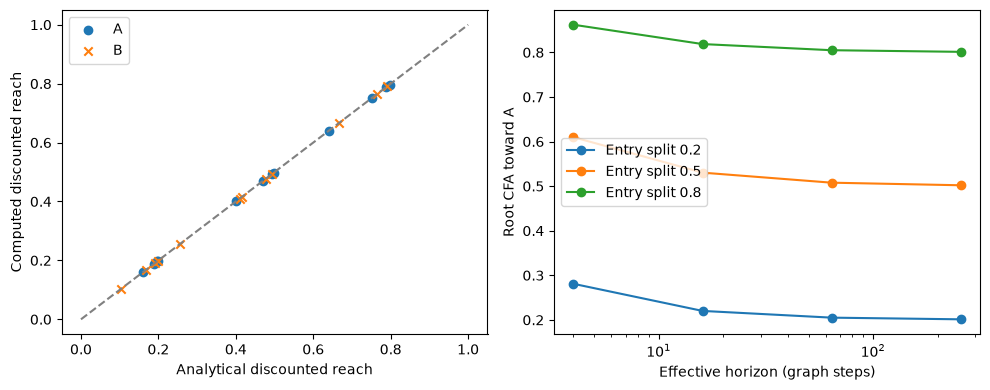

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].scatter(calibration.analytic_A, calibration.computed_A, label="A")
axes[0].scatter(calibration.analytic_B, calibration.computed_B, marker="x", label="B")
axes[0].plot([0, 1], [0, 1], color="0.5", linestyle="--")
axes[0].set(xlabel="Analytical discounted reach", ylabel="Computed discounted reach")
axes[0].legend()
for p, group in calibration.groupby("split"):
    axes[1].plot(group.h, group.CFA_A, marker="o", label=f"Entry split {p:.1f}")
axes[1].set(xscale="log", xlabel="Effective horizon (graph steps)", ylabel="Root CFA toward A")
axes[1].legend()
fig.tight_layout()
plt.show()

## Interpretation and limits
Mass conservation and agreement with the analytical result validate the solver for this chain. Finite-horizon affinity favors the nearer anchor; this is the estimand, not a numerical error. The sampled-walk discrepancy is Monte Carlo error. Exact agreement does not validate a biological velocity graph or prove irreversible commitment. See [metric definitions](https://sccs-py.readthedocs.io/en/latest/metrics.html) and [limitations](https://sccs-py.readthedocs.io/en/latest/limitations.html).


In [5]:
assert calibration.solver_max_error.max() < 1e-10
assert calibration.mass_error.max() < 1e-10
assert calibration.simulation_max_error.max() < 0.015
print("Analytical, independent-walk and conservation checks passed.")

Analytical, independent-walk and conservation checks passed.
